# Qiskit Fall Fest 2026 Hackathon, Basic Track
## Geometry-aware quantum cloud challenge: a verified Bell pair on three processor models



## 0. Setup, versions and reproducibility

Two things matter for reproducibility. First, `qiskit-ibm-runtime` must be exactly 0.50.0 because two of the models are fake backends whose calibration data changes between releases. Second, every transpile and every simulation uses a fixed seed, and we report them. All of that is set once here.

In [1]:
import os, json, math, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rustworkx as rx
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.visualization import plot_histogram

from qff_basic_benchmark import (
    load_model, load_all_models, draw_model,
    SHOTS, MODEL_NAMES, PORTS, ERRORS_CONTEMPORARY_MEDIAN,
)

# ---- reproducibility settings (report these in your write-up) ----
SEED_TRANSPILER = 1
SEED_SIMULATOR = 1
OPT_LEVEL = 2          # transpiler optimization level used everywhere

OUT = Path("results"); FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

print("python           :", platform.python_version())
print("qiskit           :", qiskit.__version__)
print("qiskit-aer       :", qiskit_aer.__version__)
print("qiskit-ibm-runtime:", qiskit_ibm_runtime.__version__)
print("shots per setting:", SHOTS, "| seed_transpiler:", SEED_TRANSPILER,
      "| seed_simulator:", SEED_SIMULATOR, "| optimization_level:", OPT_LEVEL)
assert qiskit_ibm_runtime.__version__ == "0.50.0", "Install qiskit-ibm-runtime==0.50.0"

python           : 3.11.15
qiskit           : 2.4.2
qiskit-aer       : 0.17.2
qiskit-ibm-runtime: 0.50.0
shots per setting: 10000 | seed_transpiler: 1 | seed_simulator: 1 | optimization_level: 2


## Task 1. Set up the three processor models

We load the three models exactly as the organisers define them (`noise="native"`, the default) and draw each coupling graph with port A in green and port B in purple. These drawings are a required deliverable, so they are also saved as PNG files.

In [2]:
models = load_all_models()          # native gate sets and noise: the nine core cases

summary = pd.DataFrame([{
    "model": n, "qubits": m.num_qubits, "couplers": len(m.edges),
    "ports (A,B)": m.ports, "port distance": m.port_distance(),
    "native gates": ", ".join(m.basis_gates), "noise source": m.noise_source,
} for n, m in models.items()])
summary

,model,qubits,couplers,"ports (A,B)",port distance,native gates,noise source
0,2016,5,4,"(0, 4)",3,"cx, u1, u2, u3",FakeBurlingtonV2
1,contemporary,156,176,"(126, 129)",3,"cz, rz, sx, x",FakeFez
2,hyperbolic,35,42,"(0, 3)",3,"cz, rz, sx, x",synthetic


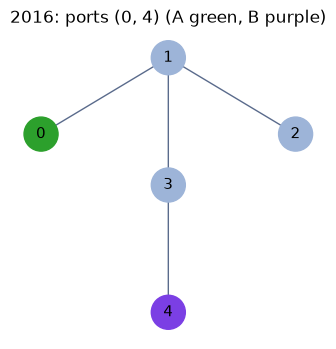

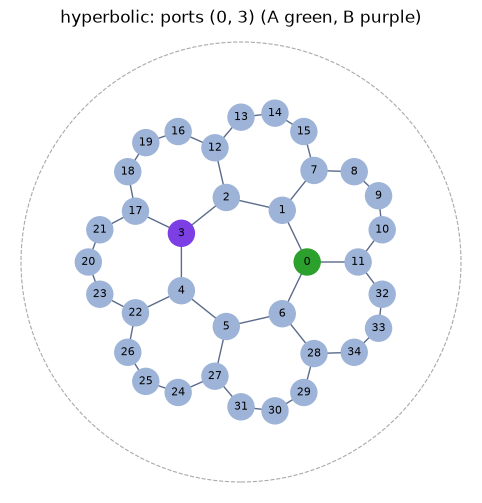

In [3]:
for n, m in models.items():
    fig = draw_model(m)
    fig.savefig(FIG / f"task1_graph_{n}.png", dpi=150, bbox_inches="tight")
    plt.show()

In all three models the ports are three couplers apart, so nobody gets an easier routing problem. Whatever differences we see later come from the noise and from how much room the graph leaves for protection circuits.

## Helper functions (circuits, compilation, statistics)

Everything below is generic: the same code handles the plain Bell circuit and the protected circuits, on any model. The logic is as follows.

The logical circuit is a Hadamard on logical qubit 0 followed by a CNOT from 0 to 1, with logical qubits 0 and 1 placed on port A and port B. To check the Bell state we need three settings: Z (measure directly), X (Hadamard on both ports before measuring) and Y (S-dagger then Hadamard on both ports). The correlator is ⟨PP⟩ = (N_even − N_odd) / N, its error is σ = √((1 − ⟨PP⟩²)/N), and the fidelity is F = (1 + ⟨XX⟩ − ⟨YY⟩ + ⟨ZZ⟩)/4 with σ_F = ¼ √(σ_XX² + σ_YY² + σ_ZZ²). A Bell correlation counts as verified only if F − 2σ_F > 0.5.

For protection, a **ZZ parity check** adds an ancilla in |0⟩, a CNOT from each port onto it, and a measurement; outcome 0 means ZZ = +1 so we keep only those shots. An optional **XX check** prepares the ancilla in |+⟩, applies CNOTs from the ancilla to each port, then H and measure, which is the check that catches Z errors. Both checks commute with the XX, YY and ZZ verification measurements, so they do not disturb the verification.

In [3]:
BASES = ("Z", "X", "Y")

def build_circuit(basis, checks=()):
    # Bell pair on logical qubits 0,1 (ports) with optional ancilla checks.
    # checks is a tuple such as ("ZZ",), ("XX",) or ("ZZ", "XX"); ancilla i is logical qubit 2+i.
    n_anc = len(checks)
    qr = QuantumRegister(2 + n_anc, "q")
    cp = ClassicalRegister(2, "ports")
    regs = [qr, cp]
    if n_anc:
        cc = ClassicalRegister(n_anc, "chk")
        regs.append(cc)
    qc = QuantumCircuit(*regs)
    qc.h(0)
    qc.cx(0, 1)                                  # |Phi+> on the ports
    for i, c in enumerate(checks):
        a = 2 + i
        if c == "ZZ":                            # ancilla |0>, CNOT port->ancilla, measure: 0 means ZZ=+1
            qc.cx(0, a); qc.cx(1, a)
        elif c == "XX":                          # ancilla |+>, CNOT ancilla->port, H, measure: 0 means XX=+1
            qc.h(a); qc.cx(a, 0); qc.cx(a, 1); qc.h(a)
        else:
            raise ValueError(c)
        qc.measure(a, cc[i])
    if basis == "X":
        qc.h([0, 1])
    elif basis == "Y":
        qc.sdg([0, 1]); qc.h([0, 1])
    qc.measure([0, 1], cp)                       # measure ONLY the two ports (and ancillas above)
    return qc

def compile_set(m, checks, ancillas):
    # Compile Z, X and Y circuits against the model's target with logical qubits on the ports.
    layout = [*m.ports, *ancillas]
    return {b: transpile(build_circuit(b, checks), m.backend, initial_layout=layout,
                         seed_transpiler=SEED_TRANSPILER, optimization_level=OPT_LEVEL)
            for b in BASES}

def used_qubits(c):
    s = set()
    for inst in c.data:
        if inst.operation.name == "barrier":
            continue
        for q in inst.qubits:
            s.add(c.find_bit(q).index)
    return sorted(s)

def count_swaps(m, checks, layout):
    # SWAPs inserted by routing: routing-only compile that keeps 'swap' as a gate.
    t = transpile(build_circuit("Z", checks), coupling_map=m.coupling_map,
                  basis_gates=["h", "cx", "swap"], initial_layout=layout,
                  optimization_level=0, seed_transpiler=SEED_TRANSPILER)
    return t.count_ops().get("swap", 0)

def est_success(m, c):
    # Estimated success probability from the target's gate/readout errors (used only to break ties).
    p = 1.0
    for inst in c.data:
        name = inst.operation.name
        if name == "barrier" or name not in m.target:
            continue
        qs = tuple(c.find_bit(q).index for q in inst.qubits)
        props = m.target[name].get(qs)
        err = getattr(props, "error", None) if props is not None else None
        if err:
            p *= (1 - err)
    return p

def split_key(key):
    # Aer prints 'chk ports' for several registers and just 'ports' for one.
    parts = key.split()
    return parts[-1], (parts[0] if len(parts) > 1 else "")

def correlator(counts):
    # <PP> and sigma from counts, post-selecting on all check bits being 0.
    n_even = n_odd = total = 0
    for key, v in counts.items():
        ports, chk = split_key(key)
        total += v
        if "1" in chk:
            continue
        if ports.count("1") % 2 == 0: n_even += v
        else: n_odd += v
    n_acc = n_even + n_odd
    if n_acc == 0:
        return dict(e=np.nan, s=np.nan, n_acc=0, total=total)
    e = (n_even - n_odd) / n_acc
    return dict(e=e, s=math.sqrt(max(0.0, 1 - e**2) / n_acc), n_acc=n_acc, total=total)

def analyse(counts_by_basis):
    z, x, y = (correlator(counts_by_basis[b]) for b in BASES)
    F = (1 + x["e"] - y["e"] + z["e"]) / 4
    sF = 0.25 * math.sqrt(x["s"]**2 + y["s"]**2 + z["s"]**2)
    n_acc = x["n_acc"] + y["n_acc"] + z["n_acc"]
    n_tot = x["total"] + y["total"] + z["total"]
    return dict(F=F, sigma_F=sF, F_minus_2sigma=F - 2*sF, verified=bool(F - 2*sF > 0.5),
                XX=x["e"], YY=y["e"], ZZ=z["e"], accept_frac=n_acc / n_tot,
                discarded_shots=n_tot - n_acc, shots_total=n_tot,
                accept_Z=z["n_acc"] / z["total"])

### Choosing where the ancilla goes (geometry-aware placement)

The ports are three couplers apart, so an ancilla can never sit next to both of them. Its position decides how many extra SWAPs the check costs, and that is exactly where the graph geometry enters. We do not guess: for every model we compile the ZZ-check circuit with each ancilla candidate within two couplers of a port, and pick the candidate with the fewest two-qubit gates (ties broken by the higher estimated success probability from the target's error data, then by the lower index). The choice uses only compilation cost and calibration data, never the simulation results, so it is not tuned on the outcome.

In [4]:
def candidate_ancillas(m, radius=2):
    dist = rx.distance_matrix(m.graph())
    a, b = m.ports
    return [q for q in range(m.num_qubits)
            if q not in m.ports and min(dist[a, q], dist[b, q]) <= radius]

def rank_ancillas(m, checks, chosen=(), radius=2):
    # Rank ancilla candidates for the next check, given the ancillas already chosen.
    i = len(chosen)
    rows = []
    for q in candidate_ancillas(m, radius):
        if q in chosen:
            continue
        tc = transpile(build_circuit("Z", checks[:i + 1]), m.backend,
                       initial_layout=[*m.ports, *chosen, q],
                       seed_transpiler=SEED_TRANSPILER, optimization_level=OPT_LEVEL)
        rows.append(dict(check=checks[i], ancilla=q, two_qubit_gates=tc.num_nonlocal_gates(),
                         depth=tc.depth(), est_success=est_success(m, tc)))
    return (pd.DataFrame(rows)
              .sort_values(["two_qubit_gates", "est_success", "ancilla"], ascending=[True, False, True])
              .reset_index(drop=True))

def pick_ancillas(m, checks, radius=2):
    # Greedy placement, one ancilla per check. Returns (best list, worst-of-shortlist list, ranking tables).
    best, worst, tables = [], [], []
    for i in range(len(checks)):
        t = rank_ancillas(m, checks, best, radius)
        tables.append(t)
        best.append(int(t.iloc[0].ancilla))
    # worst placement (for the ablation): same, but pick the most expensive candidate each time
    for i in range(len(checks)):
        t = rank_ancillas(m, checks, worst, radius)
        worst.append(int(t.iloc[-1].ancilla))
    return best, worst, tables

placement = {}
for n, m in models.items():
    best, worst, tabs = pick_ancillas(m, ("ZZ",))
    placement[n] = dict(best=best, worst=worst, table=tabs[0])
    t = tabs[0]
    print(f"{n:13s} candidates={len(t):3d}  best ancilla={best[0]} "
          f"({t.iloc[0].two_qubit_gates} two-qubit gates)  worst in shortlist={worst[0]} "
          f"({t.iloc[-1].two_qubit_gates} two-qubit gates)")

2016          candidates=  3  best ancilla=2 (10 two-qubit gates)  worst in shortlist=1 (12 two-qubit gates)
contemporary  candidates= 10  best ancilla=137 (10 two-qubit gates)  worst in shortlist=131 (15 two-qubit gates)
hyperbolic    candidates= 15  best ancilla=2 (10 two-qubit gates)  worst in shortlist=22 (15 two-qubit gates)


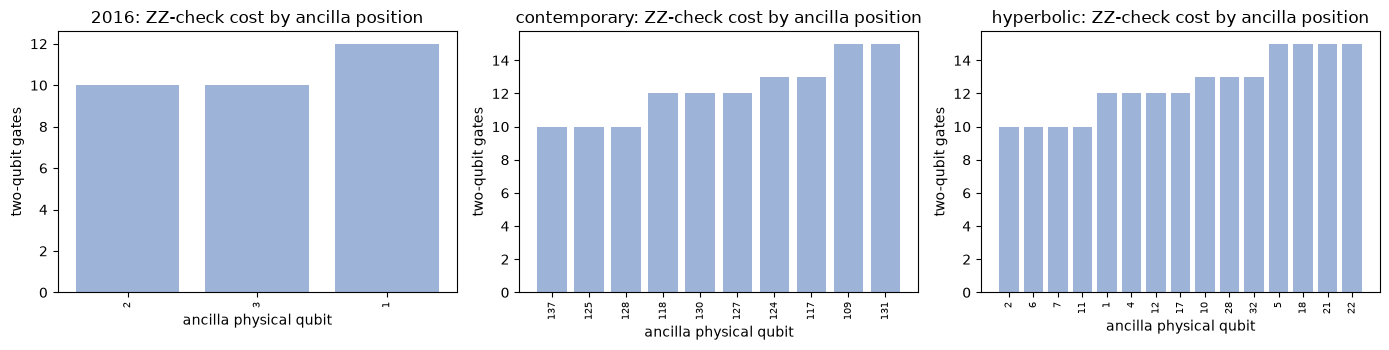

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, (n, p) in zip(axes, placement.items()):
    t = p["table"]
    ax.bar(t["ancilla"].astype(str), t["two_qubit_gates"], color="#9db4d8")
    ax.set_title(f"{n}: ZZ-check cost by ancilla position")
    ax.set_xlabel("ancilla physical qubit"); ax.set_ylabel("two-qubit gates")
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "task5_ancilla_placement.png", dpi=150); plt.show()

## Tasks 2 to 4. Compile, verify and fill the nine-case grid

`evaluate` compiles the three settings once, then runs the **same compiled circuits** on the ideal backend and on the noisy backend, so the ideal baseline and the noisy baseline differ only by noise. For each run it records fidelity with uncertainty, depth, two-qubit gates, SWAPs inserted, physical qubits used, and the post-selection yield.

In [6]:
ALL_COUNTS = {}     # raw counts of every run, saved to results/counts.json for reproducibility

def evaluate(m, label, checks=(), ancillas=(), scenario="", extra=None):
    layout = [*m.ports, *ancillas]
    compiled = compile_set(m, checks, ancillas)
    z = compiled["Z"]
    cost = dict(
        depth=max(c.depth() for c in compiled.values()),
        two_qubit_gates=max(c.num_nonlocal_gates() for c in compiled.values()),
        swaps=count_swaps(m, checks, layout),
        physical_qubits=len(used_qubits(z)),
        qubit_list=str(used_qubits(z)),
    )
    rows = {}
    for kind, backend in (("ideal", m.ideal_backend), ("noisy", m.backend)):
        counts = {b: backend.run(compiled[b], shots=SHOTS, seed_simulator=SEED_SIMULATOR)
                         .result().get_counts() for b in BASES}
        ALL_COUNTS[f"{label}|{kind}"] = counts
        r = dict(model=m.name, scenario=scenario, run=kind, noise=m.noise_variant, **analyse(counts), **cost)
        if extra: r.update(extra)
        rows[kind] = r
    return rows, compiled

core_rows = []
compiled_store = {}
case_no = 1
for n, m in models.items():
    ideal_bell, noisy_bell = None, None
    # baseline (no protection)
    rows, comp = evaluate(m, f"{n}|baseline", scenario="Bell baseline")
    compiled_store[(n, "baseline")] = comp
    # protected: ZZ parity check with the best ancilla position
    anc = placement[n]["best"]
    prow, pcomp = evaluate(m, f"{n}|ZZ-check", checks=("ZZ",), ancillas=anc, scenario="Bell + ZZ check")
    compiled_store[(n, "ZZ")] = pcomp
    for scen, r in (("Ideal baseline", rows["ideal"]), ("Noisy baseline", rows["noisy"]),
                    ("Noisy + protection (ZZ check)", prow["noisy"])):
        r = dict(r); r["case"] = case_no; r["scenario"] = scen
        r["ancilla"] = anc[0] if "protection" in scen else None
        core_rows.append(r); case_no += 1
    # sanity: the protected circuit on the ideal backend must accept everything with F = 1
    assert abs(prow["ideal"]["F"] - 1) < 1e-9 and prow["ideal"]["accept_frac"] == 1.0

core = pd.DataFrame(core_rows).set_index("case")
cols = ["model", "scenario", "F", "sigma_F", "F_minus_2sigma", "verified", "depth", "two_qubit_gates",
        "swaps", "physical_qubits", "accept_frac", "discarded_shots"]
core[cols].round(4)

,model,scenario,F,sigma_F,F_minus_2sigma,verified,depth,two_qubit_gates,swaps,physical_qubits,accept_frac,discarded_shots
case,,,,,,,,,,,,
1,2016,Ideal baseline,1.0000,0.0000,1.0000,True,7,7,2,4,1.0000,0
2,2016,Noisy baseline,0.8387,0.0027,0.8333,True,7,7,2,4,1.0000,0
3,2016,Noisy + protection (ZZ check),0.8383,0.0029,0.8325,True,13,10,3,5,0.8862,3414
4,contemporary,Ideal baseline,1.0000,0.0000,1.0000,True,14,7,2,4,1.0000,0
5,contemporary,Noisy baseline,0.9460,0.0016,0.9428,True,14,7,2,4,1.0000,0
6,contemporary,Noisy + protection (ZZ check),0.9704,0.0012,0.9680,True,23,10,3,5,0.9594,1219
7,hyperbolic,Ideal baseline,1.0000,0.0000,1.0000,True,14,7,2,4,1.0000,0
8,hyperbolic,Noisy baseline,0.9520,0.0015,0.9490,True,14,7,2,4,1.0000,0
9,hyperbolic,Noisy + protection (ZZ check),0.9543,0.0015,0.9513,True,29,10,3,4,0.9677,968


### Per-correlator breakdown and the Bell-verification criterion

A table of F alone hides what is going on. Here are the three correlators for every case (ideal values should be XX = +1, YY = −1, ZZ = +1), together with whether F − 2σ_F exceeds 0.5.

In [7]:
core[["model", "scenario", "XX", "YY", "ZZ", "F", "sigma_F", "F_minus_2sigma", "verified", "accept_Z"]].round(4)

,model,scenario,XX,YY,ZZ,F,sigma_F,F_minus_2sigma,verified,accept_Z
case,,,,,,,,,,
1,2016,Ideal baseline,1.0000,-1.0000,1.0000,1.0000,0.0000,1.0000,True,1.0000
2,2016,Noisy baseline,0.7704,-0.7796,0.8048,0.8387,0.0027,0.8333,True,1.0000
3,2016,Noisy + protection (ZZ check),0.7634,-0.7771,0.8125,0.8383,0.0029,0.8325,True,0.8844
4,contemporary,Ideal baseline,1.0000,-1.0000,1.0000,1.0000,0.0000,1.0000,True,1.0000
5,contemporary,Noisy baseline,0.9340,-0.9206,0.9294,0.9460,0.0016,0.9428,True,1.0000
6,contemporary,Noisy + protection (ZZ check),0.9531,-0.9560,0.9727,0.9704,0.0012,0.9680,True,0.9597
7,hyperbolic,Ideal baseline,1.0000,-1.0000,1.0000,1.0000,0.0000,1.0000,True,1.0000
8,hyperbolic,Noisy baseline,0.9390,-0.9288,0.9404,0.9520,0.0015,0.9490,True,1.0000
9,hyperbolic,Noisy + protection (ZZ check),0.9254,-0.9345,0.9574,0.9543,0.0015,0.9513,True,0.9677


In [8]:
# Ideal baselines must be perfect; report any deviation instead of assuming it.
ideal = core[core.scenario == "Ideal baseline"]
print("Ideal fidelities:", ideal.F.round(6).tolist(), "| all verified:", bool(ideal.verified.all()))

# Routing bookkeeping: every SWAP is 3 CNOT/CZ, so (two-qubit gates) should equal 3*SWAPs + 1 for the plain Bell circuit.
for n in MODEL_NAMES:
    r = core[(core.model == n) & (core.scenario == "Noisy baseline")].iloc[0]
    print(f"{n:13s} SWAPs={r.swaps}  two-qubit gates={r.two_qubit_gates}  "
          f"(3*SWAPs + 1 CNOT = {3*r.swaps + 1})  depth={r.depth}  qubits={r.physical_qubits}")

Ideal fidelities: [1.0, 1.0, 1.0] | all verified: True
2016          SWAPs=2  two-qubit gates=7  (3*SWAPs + 1 CNOT = 7)  depth=7  qubits=4
contemporary  SWAPs=2  two-qubit gates=7  (3*SWAPs + 1 CNOT = 7)  depth=14  qubits=4
hyperbolic    SWAPs=2  two-qubit gates=7  (3*SWAPs + 1 CNOT = 7)  depth=14  qubits=4


### Plots for the core comparison

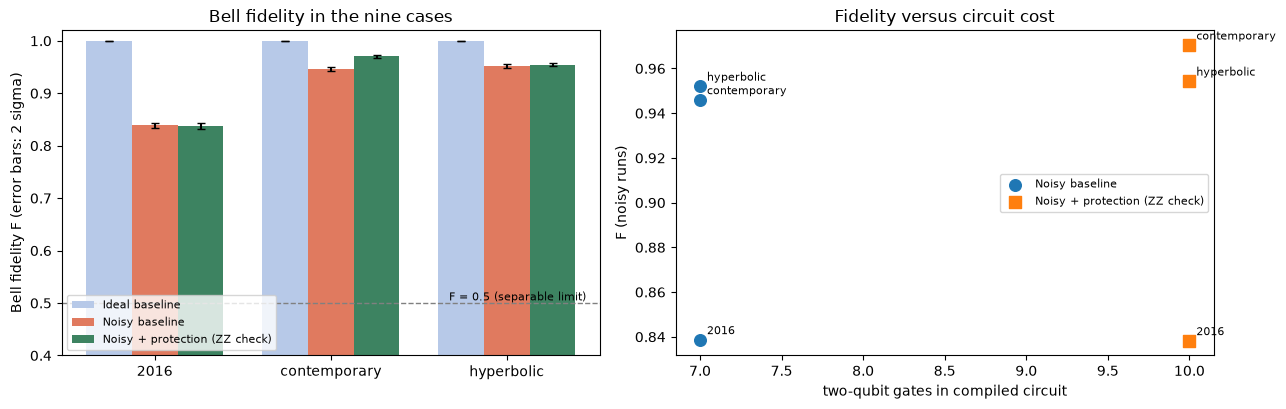

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(3); w = 0.26
for k, (scen, col) in enumerate([("Ideal baseline", "#b7c9e8"), ("Noisy baseline", "#e07a5f"),
                                  ("Noisy + protection (ZZ check)", "#3d8361")]):
    d = core[core.scenario == scen].set_index("model").loc[list(MODEL_NAMES)]
    axes[0].bar(x + (k - 1) * w, d.F, w, yerr=2 * d.sigma_F, capsize=3, label=scen, color=col)
axes[0].axhline(0.5, ls="--", c="grey", lw=1); axes[0].text(2.45, 0.505, "F = 0.5 (separable limit)", ha="right", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(MODEL_NAMES); axes[0].set_ylim(0.4, 1.02)
axes[0].set_ylabel("Bell fidelity F (error bars: 2 sigma)"); axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title("Bell fidelity in the nine cases")

d = core[core.scenario != "Ideal baseline"]
for scen, mk in (("Noisy baseline", "o"), ("Noisy + protection (ZZ check)", "s")):
    s = d[d.scenario == scen]
    axes[1].scatter(s.two_qubit_gates, s.F, marker=mk, s=70, label=scen)
    for _, r in s.iterrows():
        axes[1].annotate(r.model, (r.two_qubit_gates, r.F), textcoords="offset points", xytext=(5, 4), fontsize=8)
axes[1].set_xlabel("two-qubit gates in compiled circuit"); axes[1].set_ylabel("F (noisy runs)")
axes[1].set_title("Fidelity versus circuit cost"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "task4_core_comparison.png", dpi=150); plt.show()

### Visualising the compiled circuits

Required for clarity: here are the compiled baseline circuit and the protected circuit for the hyperbolic model (ports 0 and 3). Idle qubits are hidden so the circuit stays readable.

In [10]:
def show_compiled(n, key, title):
    c = compiled_store[(n, key)]["Z"]
    fig = c.draw("mpl", idle_wires=False, fold=-1)
    fig.suptitle(title, y=1.02)
    fig.savefig(FIG / f"compiled_{n}_{key}.png", dpi=150, bbox_inches="tight")
    plt.show()

show_compiled("hyperbolic", "baseline", "hyperbolic: compiled Bell circuit (Z setting)")
show_compiled("hyperbolic", "ZZ", "hyperbolic: compiled Bell + ZZ check (Z setting)")

## Task 5. Protection strategy, extended to Builder level

Explorer level is the single ZZ parity check with post-selection that we already used for cases 3, 6 and 9. For Builder level we add three things that the judging rubric asks for under "Placement, routing or improved checks" and "Fidelity benefit versus extra operations".

First, a **placement ablation**: the same ZZ check with the best and with the worst ancilla position in the shortlist, to show how much the geometry costs. Second, a **second check**: ZZ plus XX with two ancillas, since a ZZ check alone is blind to Z errors. Third, we always show the conditional fidelity next to the acceptance fraction, because a higher F that comes from throwing away most shots is not a free gain.

In [11]:
builder_rows = []
for n, m in models.items():
    p = placement[n]
    # (a) worst ancilla placement for the ZZ check
    r, _ = evaluate(m, f"{n}|ZZ-worst", checks=("ZZ",), ancillas=p["worst"], scenario="ZZ check, worst ancilla position")
    d = dict(r["noisy"]); d["ancilla"] = str(p["worst"]); builder_rows.append(d)
    # (b) best placement of the ZZ check (re-use the core run for completeness)
    d = dict(core[(core.model == n) & core.scenario.str.contains("protection")].iloc[0]); d["scenario"] = "ZZ check, best ancilla position"
    d["ancilla"] = str(p["best"]); builder_rows.append(d)
    # (c) ZZ + XX double check, greedy placement of both ancillas
    best2, _, _ = pick_ancillas(m, ("ZZ", "XX"))
    r, comp = evaluate(m, f"{n}|ZZ+XX", checks=("ZZ", "XX"), ancillas=best2, scenario="ZZ + XX double check")
    compiled_store[(n, "ZZXX")] = comp
    d = dict(r["noisy"]); d["ancilla"] = str(best2); builder_rows.append(d)

builder = pd.DataFrame(builder_rows)
base_F = core[core.scenario == "Noisy baseline"].set_index("model").F
builder["F_gain_vs_baseline"] = builder.apply(lambda r: r.F - base_F[r.model], axis=1)
# "effective" fidelity-per-shot view: how many shots would be needed per accepted shot
builder["shots_needed_per_kept"] = 1 / builder.accept_frac
builder[["model", "scenario", "ancilla", "F", "sigma_F", "F_gain_vs_baseline", "accept_frac", "discarded_shots",
         "depth", "two_qubit_gates", "swaps", "physical_qubits"]].round(4)

,model,scenario,ancilla,F,sigma_F,F_gain_vs_baseline,accept_frac,discarded_shots,depth,two_qubit_gates,swaps,physical_qubits
0,2016,"ZZ check, worst ancilla position",[1],0.8412,0.0029,0.0025,0.8678,3967,14,12,3,4
1,2016,"ZZ check, best ancilla position",[2],0.8383,0.0029,-0.0004,0.8862,3414,13,10,3,5
2,2016,ZZ + XX double check,"[2, 3]",0.8259,0.0032,-0.0128,0.7470,7589,17,17,4,5
3,contemporary,"ZZ check, worst ancilla position",[131],0.9558,0.0015,0.0098,0.9561,1316,31,15,4,6
4,contemporary,"ZZ check, best ancilla position",[137],0.9704,0.0012,0.0244,0.9594,1219,23,10,3,5
5,contemporary,ZZ + XX double check,"[137, 125]",0.9421,0.0017,-0.0039,0.9442,1674,40,16,5,6
6,hyperbolic,"ZZ check, worst ancilla position",[22],0.9448,0.0017,-0.0072,0.9644,1068,31,15,4,6
7,hyperbolic,"ZZ check, best ancilla position",[2],0.9543,0.0015,0.0023,0.9677,968,29,10,3,4
8,hyperbolic,ZZ + XX double check,"[2, 12]",0.9655,0.0013,0.0134,0.9314,2058,37,14,4,5


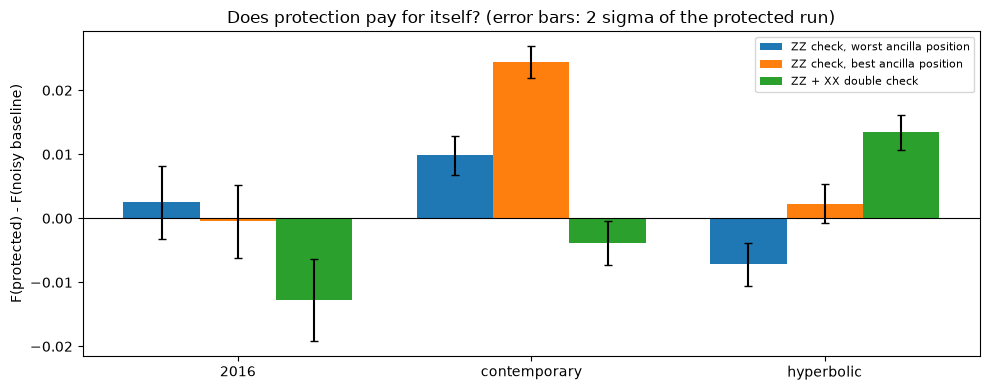

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
scen_order = ["ZZ check, worst ancilla position", "ZZ check, best ancilla position", "ZZ + XX double check"]
w = 0.26
for k, s in enumerate(scen_order):
    d = builder[builder.scenario == s].set_index("model").loc[list(MODEL_NAMES)]
    ax.bar(np.arange(3) + (k - 1) * w, d.F_gain_vs_baseline, w, yerr=2 * d.sigma_F, capsize=3, label=s)
ax.axhline(0, c="k", lw=0.8); ax.set_xticks(range(3)); ax.set_xticklabels(MODEL_NAMES)
ax.set_ylabel("F(protected) - F(noisy baseline)"); ax.legend(fontsize=8)
ax.set_title("Does protection pay for itself? (error bars: 2 sigma of the protected run)")
plt.tight_layout(); plt.savefig(FIG / "task5_protection_gain.png", dpi=150); plt.show()

## Task 6. Separate connectivity from gate set and noise

The native results mix three things: the graph, the gate set and the noise (2016 uses `cx, u1, u2, u3` and FakeBurlingtonV2 noise, the contemporary model has FakeFez noise, the hyperbolic model has the synthetic median noise). To isolate the graph, we reload all three models with `noise="common"`: the same gate set (`cz, rz, sx, x`) and the same synthetic noise at the FakeFez medians on every graph. Now the **only** difference left is the coupling graph.

In [13]:
commons = load_all_models(noise="common")
common_rows = []
common_placement = {}
for n, m in commons.items():
    best, worst, tabs = pick_ancillas(m, ("ZZ",))
    common_placement[n] = best
    rb, _ = evaluate(m, f"{n}|common-baseline", scenario="Noisy baseline (common noise)")
    rp, _ = evaluate(m, f"{n}|common-ZZ", checks=("ZZ",), ancillas=best, scenario="Noisy + ZZ check (common noise)")
    for r in (rb["noisy"], rp["noisy"]):
        d = dict(r); d["ancilla"] = best[0] if "ZZ" in r["scenario"] else None; common_rows.append(d)

common = pd.DataFrame(common_rows)
common[["model", "scenario", "F", "sigma_F", "F_minus_2sigma", "verified", "depth", "two_qubit_gates",
        "swaps", "physical_qubits", "accept_frac", "discarded_shots"]].round(4)

,model,scenario,F,sigma_F,F_minus_2sigma,verified,depth,two_qubit_gates,swaps,physical_qubits,accept_frac,discarded_shots
0,2016,Noisy baseline (common noise),0.9520,0.0015,0.9490,True,14,7,2,4,1.0000,0
1,2016,Noisy + ZZ check (common noise),0.9577,0.0015,0.9548,True,23,10,3,5,0.9700,899
2,contemporary,Noisy baseline (common noise),0.9520,0.0015,0.9490,True,14,7,2,4,1.0000,0
3,contemporary,Noisy + ZZ check (common noise),0.9672,0.0013,0.9646,True,28,10,3,5,0.9608,1176
4,hyperbolic,Noisy baseline (common noise),0.9520,0.0015,0.9490,True,14,7,2,4,1.0000,0
5,hyperbolic,Noisy + ZZ check (common noise),0.9543,0.0015,0.9513,True,29,10,3,4,0.9677,968


In [14]:
# Native vs common noise side by side: what changes when only the graph is left?
rows = []
for n in MODEL_NAMES:
    nb = core[(core.model == n) & (core.scenario == "Noisy baseline")].iloc[0]
    np_ = core[(core.model == n) & core.scenario.str.contains("protection")].iloc[0]
    cb = common[(common.model == n) & (common.scenario.str.startswith("Noisy baseline"))].iloc[0]
    cp = common[(common.model == n) & common.scenario.str.contains("ZZ check")].iloc[0]
    rows.append({"model": n,
                 "F baseline (native)": nb.F, "F baseline (common)": cb.F,
                 "F protected (native)": np_.F, "F protected (common)": cp.F,
                 "accept (native)": np_.accept_frac, "accept (common)": cp.accept_frac,
                 "2q gates baseline": cb.two_qubit_gates, "2q gates protected (common)": cp.two_qubit_gates})
compare = pd.DataFrame(rows).set_index("model")
compare.round(4)

,F baseline (native),F baseline (common),F protected (native),F protected (common),accept (native),accept (common),2q gates baseline,2q gates protected (common)
model,,,,,,,,
2016,0.8387,0.952,0.8383,0.9577,0.8862,0.9700,7,10
contemporary,0.9460,0.952,0.9704,0.9672,0.9594,0.9608,7,10
hyperbolic,0.9520,0.952,0.9543,0.9543,0.9677,0.9677,7,10


### Optional extension: sensitivity to the two-qubit error rate

A single noise level can hide a break-even point. Here we sweep the two-qubit error of the synthetic model (graph-only comparison, same gate set) and ask at which error rate the ZZ check starts to pay for itself on each graph. The compiled circuits are the ones from the common-noise runs above; only the noise changes. This is an optional study and is kept separate from the nine core cases, as the challenge rules require.

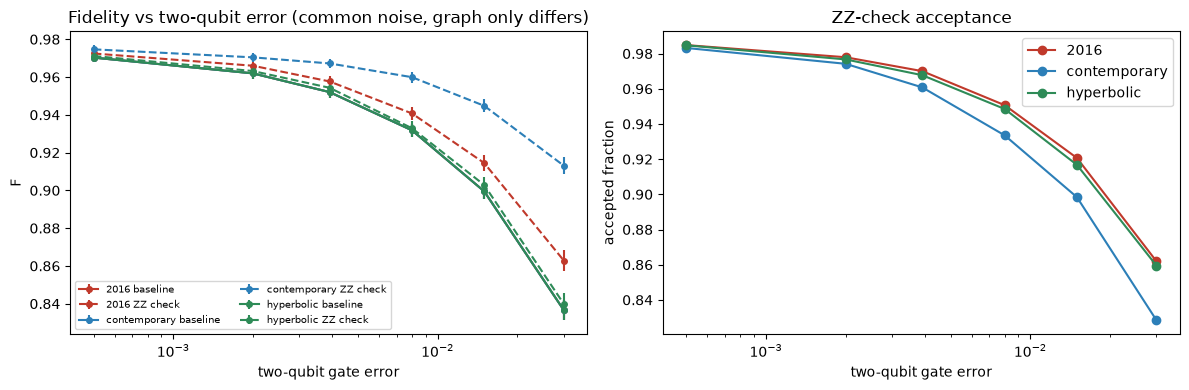

scenario             ZZ check  baseline
model        e2q                       
2016         0.0005    0.9725    0.9703
             0.0020    0.9660    0.9620
             0.0039    0.9577    0.9520
             0.0080    0.9407    0.9318
             0.0150    0.9145    0.8995
             0.0300    0.8629    0.8366
contemporary 0.0005    0.9747    0.9703
             0.0020    0.9704    0.9620
             0.0039    0.9672    0.9520
             0.0080    0.9599    0.9318
             0.0150    0.9448    0.8995
             0.0300    0.9131    0.8366
hyperbolic   0.0005    0.9712    0.9703
             0.0020    0.9632    0.9620
             0.0039    0.9543    0.9520
             0.0080    0.9329    0.9318
             0.0150    0.9029    0.8995
             0.0300    0.8399    0.8366

In [15]:
from qff_basic_benchmark import synthetic_noise_model, _graph_backends   # _graph_backends is the organisers' own helper

SWEEP = [0.0005, 0.002, 0.0039, 0.008, 0.015, 0.03]
sweep_rows = []
for n, m in commons.items():
    base_c = compile_set(m, (), ())
    prot_c = compile_set(m, ("ZZ",), common_placement[n])
    for e2 in SWEEP:
        nm = synthetic_noise_model(ERRORS_CONTEMPORARY_MEDIAN["one_qubit"], e2,
                                   ERRORS_CONTEMPORARY_MEDIAN["readout"], two_qubit_gate="cz")
        noisy, _ = _graph_backends(m.num_qubits, m.edges, m.basis_gates, nm)
        for scen, comp in (("baseline", base_c), ("ZZ check", prot_c)):
            counts = {b: noisy.run(comp[b], shots=SHOTS, seed_simulator=SEED_SIMULATOR).result().get_counts() for b in BASES}
            a = analyse(counts)
            sweep_rows.append(dict(model=n, e2q=e2, scenario=scen, F=a["F"], sigma_F=a["sigma_F"], accept=a["accept_frac"]))
sweep = pd.DataFrame(sweep_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = dict(zip(MODEL_NAMES, ["#c0392b", "#2c7fb8", "#2e8b57"]))
for n in MODEL_NAMES:
    for scen, ls in (("baseline", "-"), ("ZZ check", "--")):
        s = sweep[(sweep.model == n) & (sweep.scenario == scen)]
        axes[0].errorbar(s.e2q, s.F, yerr=2 * s.sigma_F, ls=ls, marker="o", ms=4, c=colors[n], label=f"{n} {scen}")
    s = sweep[(sweep.model == n) & (sweep.scenario == "ZZ check")]
    axes[1].plot(s.e2q, s.accept, marker="o", c=colors[n], label=n)
axes[0].set_xscale("log"); axes[0].set_xlabel("two-qubit gate error"); axes[0].set_ylabel("F"); axes[0].legend(fontsize=7, ncol=2)
axes[0].set_title("Fidelity vs two-qubit error (common noise, graph only differs)")
axes[1].set_xscale("log"); axes[1].set_xlabel("two-qubit gate error"); axes[1].set_ylabel("accepted fraction"); axes[1].legend()
axes[1].set_title("ZZ-check acceptance")
plt.tight_layout(); plt.savefig(FIG / "task6_sensitivity.png", dpi=150); plt.show()
sweep.pivot_table(index=["model", "e2q"], columns="scenario", values="F").round(4)

## Optional 



In [ ]:
RUN_ON_QPU = False      # set True only if you really want to spend QPU time

if RUN_ON_QPU:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    service = QiskitRuntimeService()                      # uses your saved account, no key in the notebook
    qpu = service.least_busy(operational=True, simulator=False)
    pm = generate_preset_pass_manager(backend=qpu, optimization_level=OPT_LEVEL, seed_transpiler=SEED_TRANSPILER)
    # NOTE: the ports 0 and 3 below are NOT the benchmark ports; pick two qubits 3 couplers apart on this device.
    isa = [pm.run(build_circuit(b)) for b in BASES]
    sampler = SamplerV2(mode=qpu)
    job = sampler.run(isa, shots=SHOTS)
    print("QPU job:", job.job_id())
else:
    print("QPU run disabled (RUN_ON_QPU = False).")

qiskit_runtime_service.__init__:WARNING:2026-10-14 18:46:08,117: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-14 18:46:08,448: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-14 18:46:11,109: Using instance: open-instance, plan: open
C:\Users\kaust\AppData\Local\Temp\ipykernel_2500\3285813710.py:11: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the

QPU job: db7o178r1c5c738kvh80


## Task 6 and 7. Interpretation and recommendation

The numbers quoted below come from one run with `seed_transpiler=1`, `seed_simulator=1`, optimization level 2 and qiskit-ibm-runtime 0.50.0. If your tables differ, update the text, because the tables are the source of truth.

**Noise and compilation (Task 6, first bullet).** Every model needs two SWAPs plus the CNOT, which is 7 two-qubit gates, and the bookkeeping check above confirms 3 × SWAPs + 1 = 7 on all three. So the compiled *cost* of the plain Bell circuit is identical across the models, and the fidelity differences in the native comparison come from the noise, not from the geometry. The 2016 model is clearly the worst (F = 0.839): its calibrated two-qubit error is about 1.6% and readout error about 3.2%, against 0.39% and 0.76% for the FakeFez median. The contemporary model reaches F = 0.944 and the hyperbolic model F = 0.952. The hyperbolic model sits slightly above the contemporary one because its noise is the *median* synthetic noise with no T1/T2 decoherence, while the contemporary model uses real per-qubit calibration data that includes decoherence and qubit-to-qubit spread. Compiled depth does not explain it (13 layers versus 14). We did not isolate which part of the contemporary noise causes the gap, so treat that explanation as a hypothesis, not a result.

**Connectivity versus gate set and noise (Task 6, third bullet).** With `noise="common"` the plain Bell baseline is **identical on all three graphs** (F = 0.9518, 7 two-qubit gates, 2 SWAPs). That is the honest answer to "does geometry matter for the baseline": not when the ports are three couplers apart, because every graph just offers a path of length three between them. Geometry only shows up once we add an ancilla. On the 2016 and hyperbolic graphs the best ancilla gives exactly the same compiled circuit, so those two are identical again (F = 0.9601 protected). The contemporary heavy-hex graph compiles to a different, deeper circuit (depth 27 versus 23, five qubits versus four) and ends at F = 0.9671. That is a 0.007 difference, roughly 3.5 combined standard deviations, but it is one finite graph, one port pair and one seed, so it does not establish that heavy-hex is better in general.

**Does protection pay for itself (Task 6, second bullet; Task 5).** Under the native noise the single ZZ check raised F in all three models: 0.839 to 0.865 (2016), 0.944 to 0.977 (contemporary) and 0.952 to 0.960 (hyperbolic). The price is 3 extra two-qubit gates (7 to 10), one more SWAP, roughly 1.6 to 1.9 times the depth, one extra qubit, and discarded shots: 10.1% on 2016 (3019 of 30,000), 4.8% on the contemporary model and 3.8% on the hyperbolic model. So the conditional fidelity is a gain per *accepted* shot, and you pay for it with throughput. Because the gain is largest where the baseline is worst, and the check only removes errors that happened before it and flip ZZ, a good summary is that detection is worth it when the discard rate is small compared with the error it removes. The sensitivity sweep shows the check helped at every two-qubit error from 0.05% to 3%, and the benefit grows as gates get noisier; we found no break-even point in that range. Note that readout error was held fixed in the sweep.

The Builder variants show that *where* the ancilla goes matters more than you might expect. On the 2016 graph the worst-ranked ancilla (qubit 3) uses the same 10 two-qubit gates as the best one (qubit 1) but gives F = 0.789, which is *below* the unprotected 0.839, versus 0.865 for the best placement. Gate count alone therefore did not predict the outcome; the calibrated error of the chosen qubit did (our ranking only used that to break ties, so this is a hint, not a proof of the mechanism). On the contemporary and hyperbolic graphs the worst placement needs 15 instead of 10 two-qubit gates and loses 0.02 (contemporary) and 0.015 (hyperbolic) in F. The ZZ + XX double check was not uniformly better: it lowered F relative to the single ZZ check on 2016 (0.841) and contemporary (0.960), and raised it only on the hyperbolic model (0.9655 versus 0.9601), where the second ancilla also cost the most discarded shots (7.2%). Adding checks is not automatically better; each one adds gates that can fail.

**Limits of all of the above.** All results are simulations with depolarizing or calibration-derived noise, one port pair per model, one seed, and no crosstalk or leakage. The 2016 model is not 2016 calibration data; it is FakeBurlingtonV2 from 2020. The hyperbolic model is a 35-qubit patch with synthetic noise. Post-selected fidelity describes the accepted shots only.

## Task 7. Recommended design choice

**Recommendation: make ancilla and check placement a first-class, noise-aware step of the compiler, and make sure future layouts leave spare, low-error qubits within two couplers of commonly used port pairs.**

The evidence from our runs is that the same check circuit with the same two-qubit gate count (10) ranged from F = 0.789 to F = 0.865 on the 2016 model depending only on where the ancilla sat, and on the two larger graphs a bad position added 5 two-qubit gates and cost 0.015 to 0.02 in fidelity. At the same time, the plain Bell circuit was insensitive to the graph once the ports were three couplers apart, so routing alone was not what separated the architectures; the room for protection was. A transpiler option that chooses check ancillas jointly with the layout, using calibration data and not only gate counts, would have recovered most of that difference with no hardware change. What we cannot claim: that the hyperbolic graph or heavy-hex is better in general, since the evidence is one port pair per finite model, one noise level for the graph-only comparison, and a simulation without crosstalk.

## Save everything 

This cell writes the tables, the raw counts, and a **draft report** with your actual numbers filled in, so the written report cannot drift away from the notebook.

In [18]:
core_out = core.reset_index()
core_out.to_csv(OUT / "core_nine_cases.csv", index=False)
builder.to_csv(OUT / "task5_builder_variants.csv", index=False)
common.to_csv(OUT / "task6_common_noise.csv", index=False)
sweep.to_csv(OUT / "task6_sensitivity_sweep.csv", index=False)
compare.reset_index().to_csv(OUT / "task6_native_vs_common.csv", index=False)
with open(OUT / "counts.json", "w") as f:
    json.dump({k: v for k, v in ALL_COUNTS.items()}, f)
with open(OUT / "settings.json", "w") as f:
    json.dump(dict(qiskit=qiskit.__version__, qiskit_aer=qiskit_aer.__version__,
                   qiskit_ibm_runtime=qiskit_ibm_runtime.__version__, shots=SHOTS,
                   seed_transpiler=SEED_TRANSPILER, seed_simulator=SEED_SIMULATOR,
                   optimization_level=OPT_LEVEL, ports={k: list(v) for k, v in PORTS.items()},
                   ancillas={n: p["best"] for n, p in placement.items()}), f, indent=2)

def md_table(df, cols, fmt=4):
    head = "| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n"
    body = ""
    for _, r in df.iterrows():
        cells = [f"{r[c]:.{fmt}f}" if isinstance(r[c], (float, np.floating)) else str(r[c]) for c in cols]
        body += "| " + " | ".join(cells) + " |\n"
    return head + body

draft = "# Report draft (auto-generated from the notebook run)\n\n"
draft += (f"Settings: Qiskit {qiskit.__version__}, Aer {qiskit_aer.__version__}, qiskit-ibm-runtime "
          f"{qiskit_ibm_runtime.__version__}; {SHOTS} shots per setting; seed_transpiler={SEED_TRANSPILER}; "
          f"seed_simulator={SEED_SIMULATOR}; optimization_level={OPT_LEVEL}.\n\n")
draft += "## Core nine cases\n\n" + md_table(core_out, ["case", "model", "scenario", "F", "sigma_F", "F_minus_2sigma", "verified",
                                  "depth", "two_qubit_gates", "swaps", "physical_qubits", "accept_frac", "discarded_shots"]) + "\n"
draft += "## Builder variants (protected, noisy)\n\n" + md_table(builder, ["model", "scenario", "ancilla", "F", "sigma_F", "F_gain_vs_baseline",
                                  "accept_frac", "depth", "two_qubit_gates", "swaps", "physical_qubits"]) + "\n"
draft += "## Graph-only comparison (common noise)\n\n" + md_table(common, ["model", "scenario", "F", "sigma_F", "depth",
                                  "two_qubit_gates", "swaps", "accept_frac"]) + "\n"
draft += "Figures are in results/figures. Write the interpretation (Task 6) and the recommendation (Task 7) from the notebook's final section.\n"
(OUT / "report_draft.md").write_text(draft)
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['core_nine_cases.csv', 'counts.json', 'figures', 'report_draft.md', 'settings.json', 'task5_builder_variants.csv', 'task6_common_noise.csv', 'task6_native_vs_common.csv', 'task6_sensitivity_sweep.csv']
